# Proyecto Ciberseguridad - Mineria de Datos

El trabajo busca responder los siguientes interrogantes planteados en la consigna:
1.	Ante la exfiltración inminente de datos, la ejecución de comandos inusuales o transferencias de volúmenes atípicos, ¿se puede predecir un porcentaje de vulnerabilidad del sistema?

2.	¿Con qué precisión se puede realizar esta predicción?

3.	¿Se puede aislar automáticamente el equipo afectado de la red y cambiar las políticas de firewall en tiempo real?


# Fase 1 - EDA

## 1.1 Exploracion Del Dataset

In [ ]:
!pip install gdown -q

import gdown
import pandas as pd

file_id_train = '1IN8eYjkpqV9dw4E9kkvIZ8gkynh3lMg2'
file_id_test  = '16dQko7J9fCoYOz5GfhLpquz22DoVisbX'

# Descarga el archivo a un nombre local
gdown.download(id=file_id_train, output='KDDTrain+.csv', quiet=False)
gdown.download(id=file_id_test,  output='KDDTest+.csv',  quiet=False)

df_train = pd.read_csv('KDDTrain+.csv')
df_test  = pd.read_csv('KDDTest+.csv')

print(f"Train: {df_train.shape}")
print(f"Test:  {df_test.shape}")

Downloading...
From: https://drive.google.com/uc?id=1IN8eYjkpqV9dw4E9kkvIZ8gkynh3lMg2
To: /content/KDDTrain+.csv
100%|██████████| 18.5M/18.5M [00:00<00:00, 66.1MB/s]
Downloading...
From: https://drive.google.com/uc?id=16dQko7J9fCoYOz5GfhLpquz22DoVisbX
To: /content/KDDTest+.csv
100%|██████████| 3.32M/3.32M [00:00<00:00, 20.7MB/s]


Train: (125973, 44)
Test:  (22544, 44)


In [ ]:
# 1. Dimensiones

print(f"Train: {df_train.shape[0]:,} filas × {df_train.shape[1]} columnas")
print(f"Test:  {df_test.shape[0]:,} filas  × {df_test.shape[1]} columnas")


Train: 125,973 filas × 44 columnas
Test:  22,544 filas  × 44 columnas


In [ ]:
# 2. Tipos de datos y valores nulos

df_train.info()

print(f"\nValores nulos en train: {df_train.isnull().sum().sum()}")
print(f"Duplicados en train:    {df_train.duplicated().sum()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 44 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Unnamed: 0                   125973 non-null  int64  
 1   duration                     125973 non-null  int64  
 2   protocol_type                125973 non-null  object 
 3   service                      125973 non-null  object 
 4   flag                         125973 non-null  object 
 5   src_bytes                    125973 non-null  int64  
 6   dst_bytes                    125973 non-null  int64  
 7   land                         125973 non-null  int64  
 8   wrong_fragment               125973 non-null  int64  
 9   urgent                       125973 non-null  int64  
 10  hot                          125973 non-null  int64  
 11  num_failed_logins            125973 non-null  int64  
 12  logged_in                    125973 non-null  int64  
 13 

In [ ]:
# 3. Variables categóricas
for col in ['protocol_type', 'service', 'flag']:
    print(f"\n{col} ({df_train[col].nunique()} valores únicos):")
    print(f"  {list(df_train[col].unique())}")


protocol_type (3 valores únicos):
  ['tcp', 'udp', 'icmp']

service (70 valores únicos):
  ['ftp_data', 'other', 'private', 'http', 'remote_job', 'name', 'netbios_ns', 'eco_i', 'mtp', 'telnet', 'finger', 'domain_u', 'supdup', 'uucp_path', 'Z39_50', 'smtp', 'csnet_ns', 'uucp', 'netbios_dgm', 'urp_i', 'auth', 'domain', 'ftp', 'bgp', 'ldap', 'ecr_i', 'gopher', 'vmnet', 'systat', 'http_443', 'efs', 'whois', 'imap4', 'iso_tsap', 'echo', 'klogin', 'link', 'sunrpc', 'login', 'kshell', 'sql_net', 'time', 'hostnames', 'exec', 'ntp_u', 'discard', 'nntp', 'courier', 'ctf', 'ssh', 'daytime', 'shell', 'netstat', 'pop_3', 'nnsp', 'IRC', 'pop_2', 'printer', 'tim_i', 'pm_dump', 'red_i', 'netbios_ssn', 'rje', 'X11', 'urh_i', 'http_8001', 'aol', 'http_2784', 'tftp_u', 'harvest']

flag (11 valores únicos):
  ['SF', 'S0', 'REJ', 'RSTR', 'SH', 'RSTO', 'S1', 'RSTOS0', 'S3', 'S2', 'OTH']


In [ ]:
# 4. Etiqueta original — tipos de ataque
print(df_train['label'].value_counts().to_string())

label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2


In [ ]:
# 5. Crear etiqueta binaria: normal vs attack
df_train['target'] = df_train['label'].apply(
    lambda x: 'normal' if x == 'normal' else 'attack'
)
df_test['target'] = df_test['label'].apply(
    lambda x: 'normal' if x == 'normal' else 'attack'
)


dist_train = df_train['target'].value_counts()
dist_test  = df_test['target'].value_counts()
print(f"Train → {dist_train.to_dict()}")
print(f"Test  → {dist_test.to_dict()}")
print(f"\nTrain: {dist_train['attack']/len(df_train)*100:.1f}% ataques")
print(f"Test:  {dist_test['attack']/len(df_test)*100:.1f}% ataques")

Train → {'normal': 67343, 'attack': 58630}
Test  → {'attack': 12833, 'normal': 9711}

Train: 46.5% ataques
Test:  56.9% ataques


In [ ]:
# 6. Estadísticas variables numéricas clave
print("6. ESTADÍSTICAS VARIABLES NUMÉRICAS CLAVE")

cols_num = ['duration', 'src_bytes', 'dst_bytes',
            'count', 'srv_count', 'serror_rate', 'rerror_rate']
print(df_train[cols_num].describe().round(4).to_string())

6. ESTADÍSTICAS VARIABLES NUMÉRICAS CLAVE
          duration     src_bytes     dst_bytes        count    srv_count  serror_rate  rerror_rate
count  125973.0000  1.259730e+05  1.259730e+05  125973.0000  125973.0000  125973.0000  125973.0000
mean      287.1447  4.556674e+04  1.977911e+04      84.1076      27.7379       0.2845       0.1200
std      2604.5153  5.870331e+06  4.021269e+06     114.5086      72.6358       0.4465       0.3204
min         0.0000  0.000000e+00  0.000000e+00       0.0000       0.0000       0.0000       0.0000
25%         0.0000  0.000000e+00  0.000000e+00       2.0000       2.0000       0.0000       0.0000
50%         0.0000  4.400000e+01  0.000000e+00      14.0000       8.0000       0.0000       0.0000
75%         0.0000  2.760000e+02  5.160000e+02     143.0000      18.0000       1.0000       0.0000
max     42908.0000  1.379964e+09  1.309937e+09     511.0000     511.0000       1.0000       1.0000


In [ ]:
# 7. Columna difficulty
print("\n" + "=" * 55)
print("7. COLUMNA DIFFICULTY")
print("=" * 55)
print(df_train['difficulty'].value_counts().sort_index().to_string())
print("\n→ Esta columna indica cuán difícil es clasificar cada registro.")
print("→ NO se usa como variable predictora — se elimina en el preprocesamiento.")


7. COLUMNA DIFFICULTY
difficulty
0        66
1        62
2        54
3        65
4        79
5        81
6        96
7       118
8       106
9       194
10      253
11      641
12      729
13      451
14      674
15     3990
16     2393
17     3074
18    20667
19    10284
20    19339
21    62557

→ Esta columna indica cuán difícil es clasificar cada registro.
→ NO se usa como variable predictora — se elimina en el preprocesamiento.


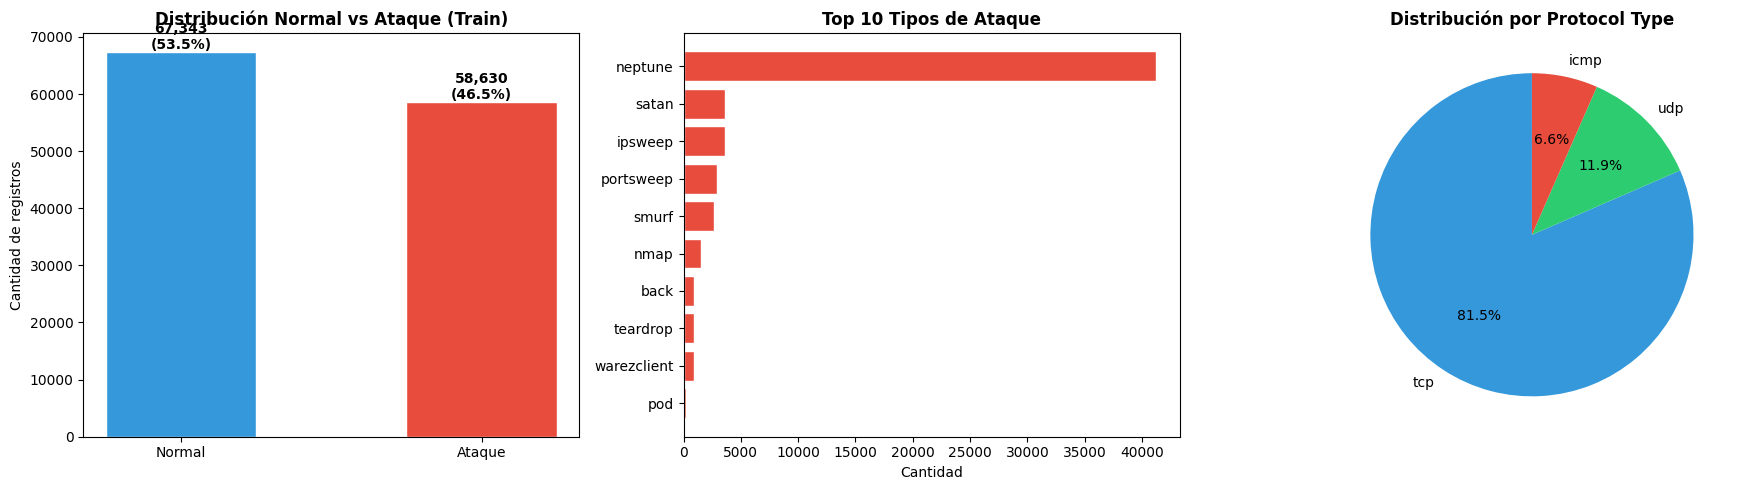

In [ ]:
# ============================================================
# GRÁFICOS EDA
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribución binaria
colores = ['#3498db', '#e74c3c']
axes[0].bar(['Normal', 'Ataque'],
            [dist_train['normal'], dist_train['attack']],
            color=colores, edgecolor='white', width=0.5)
axes[0].set_title('Distribución Normal vs Ataque (Train)', fontweight='bold')
axes[0].set_ylabel('Cantidad de registros')
for i, v in enumerate([dist_train['normal'], dist_train['attack']]):
    axes[0].text(i, v + 500, f'{v:,}\n({v/len(df_train)*100:.1f}%)',
                 ha='center', fontweight='bold')

# Tipos de ataque (top 10)
top_ataques = df_train[df_train['label'] != 'normal']['label'].value_counts().head(10)
axes[1].barh(top_ataques.index, top_ataques.values, color='#e74c3c', edgecolor='white')
axes[1].invert_yaxis()
axes[1].set_title('Top 10 Tipos de Ataque', fontweight='bold')
axes[1].set_xlabel('Cantidad')

# Distribución de protocol_type
proto_counts = df_train['protocol_type'].value_counts()
axes[2].pie(proto_counts.values,
            labels=proto_counts.index,
            autopct='%1.1f%%',
            colors=['#3498db', '#2ecc71', '#e74c3c'],
            startangle=90)
axes[2].set_title('Distribución por Protocol Type', fontweight='bold')

plt.tight_layout()
plt.show()

## 1.2 Limpieza Y Preprocesamiento


DECISIONES DE LIMPIEZA:
1. Eliminar columna 'difficulty' → no es variable de red
2. Eliminar columna 'label' → la reemplazamos por 'target' (binaria)
3. Encoding de variables categóricas
4. Guardar CSV limpio

In [ ]:
# PASO 1 — Trabajamos sobre copias
df_train_clean = df_train.copy()
df_test_clean  = df_test.copy()

In [ ]:
# PASO 2 — Eliminar columnas que no usamos
df_train_clean = df_train_clean.drop(columns=['difficulty', 'label','Unnamed: 0'])
df_test_clean  = df_test_clean.drop(columns=['difficulty', 'label','Unnamed: 0',])

print(f"Train: {df_train_clean.shape}")
print(f"Test:  {df_test_clean.shape}")

# De 43 columnas pasamos a 41 (quitamos difficulty y label, queda target)

Train: (125973, 42)
Test:  (22544, 42)


In [ ]:
# PASO 3 — Label Encoding para protocol_type
# Solo 3 valores (tcp, udp, icmp) → 0, 1, 2

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

# fit en train, transform en ambos (mismo criterio que MinMaxScaler)
df_train_clean['protocol_type'] = le.fit_transform(df_train_clean['protocol_type'])
df_test_clean['protocol_type']  = le.transform(df_test_clean['protocol_type'])

print("\nprotocol_type después del Label Encoding:")
print(f"  Clases aprendidas: {le.classes_}")
print(f"  Valores únicos en train: {sorted(df_train_clean['protocol_type'].unique())}")


protocol_type después del Label Encoding:
  Clases aprendidas: ['icmp' 'tcp' 'udp']
  Valores únicos en train: [np.int64(0), np.int64(1), np.int64(2)]


In [ ]:
# PASO 4 — One-Hot Encoding para service y flag

# service: 70 valores → 69 columnas nuevas
# flag:    11 valores → 10 columnas nuevas

# Combinamos train y test antes del get_dummies para garantizar que ambos tengan exactamente las mismas columnas
# (el test puede tener categorías que el train no tiene y viceversa)

df_train_clean['_split'] = 'train'
df_test_clean['_split']  = 'test'

df_combined = pd.concat([df_train_clean, df_test_clean], ignore_index=True)

df_combined = pd.get_dummies(df_combined,
                              columns=['service', 'flag'],
                              drop_first=True,
                              dtype=int)

# Separamos de nuevo
df_train_clean = df_combined[df_combined['_split'] == 'train'].drop(columns=['_split'])
df_test_clean  = df_combined[df_combined['_split'] == 'test'].drop(columns=['_split'])

df_train_clean = df_train_clean.reset_index(drop=True)
df_test_clean  = df_test_clean.reset_index(drop=True)


print(f"Train: {df_train_clean.shape[0]:,} filas × {df_train_clean.shape[1]} columnas")
print(f"Test:  {df_test_clean.shape[0]:,} filas × {df_test_clean.shape[1]} columnas")
print(f"\nColumnas generadas por One-Hot (service + flag):")

service_cols = [c for c in df_train_clean.columns if c.startswith('service_')]
flag_cols    = [c for c in df_train_clean.columns if c.startswith('flag_')]

print(f"  service_* : {len(service_cols)} columnas")
print(f"  flag_*    : {len(flag_cols)} columnas")

Train: 125,973 filas × 119 columnas
Test:  22,544 filas × 119 columnas

Columnas generadas por One-Hot (service + flag):
  service_* : 69 columnas
  flag_*    : 10 columnas


In [ ]:
# PASO 5 — Verificar tipos de datos finales
print("\nTipos de datos después de la limpieza:")
print(df_train_clean.dtypes.value_counts())


Tipos de datos después de la limpieza:
int64      103
float64     15
object       1
Name: count, dtype: int64


In [ ]:
# PASO 6 — Verificar que target quedó bien
print(f"\nDistribución target en train:")
print(df_train_clean['target'].value_counts())
print(f"\nDistribución target en test:")
print(df_test_clean['target'].value_counts())


Distribución target en train:
target
normal    67343
attack    58630
Name: count, dtype: int64

Distribución target en test:
target
attack    12833
normal     9711
Name: count, dtype: int64


In [ ]:
# PASO 7 — Guardar datasets limpios

# ruta_out = r'C:\Users\leand\Desktop\Proyecto_Ciberseguridad\data\nsl-kdd'

# df_train_clean.to_csv(f'{ruta_out}\KDDTrain_clean.csv', index=False)
# df_test_clean.to_csv(f'{ruta_out}\KDDTest_clean.csv',   index=False)

# print(f"\n Datasets limpios guardados en {ruta_out}")

In [ ]:

# PASO 8 — Convertir target a numérico (0/1)

# attack = 1, normal = 0
# Lógica de negocio: el "positivo" es el ataque (lo que queremos detectar)

df_train_clean['target'] = df_train_clean['target'].map(
    {'normal': 0, 'attack': 1}
)

df_test_clean['target'] = df_test_clean['target'].map(
    {'normal': 0, 'attack': 1}
)

print("Target después de la conversión:")
print(f"  Train: {df_train_clean['target'].value_counts().to_dict()}")
print(f"  Test:  {df_test_clean['target'].value_counts().to_dict()}")
print(f"\n  Tipos: {df_train_clean['target'].dtype}")



Target después de la conversión:
  Train: {0: 67343, 1: 58630}
  Test:  {1: 12833, 0: 9711}

  Tipos: int64


In [ ]:
# Verificar que no quedó ninguna columna de texto
str_cols = df_train_clean.select_dtypes(include='object').columns.tolist()
if str_cols:
    print(f"\n  Columnas str pendientes: {str_cols}")
else:
    print("\n Todas las columnas son numéricas")


 Todas las columnas son numéricas


## Conclusión — Fase 1: EDA y Limpieza



**Dataset:** NSL-KDD — tráfico de red con 125.973 registros de entrenamiento
y 22.544 de test. Cada registro representa una conexión de red con 41
características que describen su comportamiento.

**Hallazgos del EDA:**
- Sin valores nulos ni duplicados → dataset de alta calidad, no requirió
  imputación ni eliminación de registros
- 3 variables categóricas: protocol_type (3 valores), flag (11 valores),
  service (70 valores)
- Distribución de clases casi balanceada en train (53.5% normal / 46.5%
  ataques)
- 23 tipos de ataque distintos agrupados en 4 categorías:
  DoS, Probe, R2L y U2R

**Decisiones de limpieza:**
- Se eliminó `difficulty` → métrica interna del dataset, no representa
  tráfico real de red
- Se eliminó `label` (multiclase) → se reemplazó por `target` binaria
  (0=normal, 1=ataque) para clasificación binaria
- Label Encoding en `protocol_type` (3 valores, sin orden)
- One-Hot Encoding en `service` (70 valores) y `flag` (11 valores)
  combinando train y test antes del encoding para garantizar columnas
  idénticas en ambos sets
- Conversión de `target` a int64 (0/1) para compatibilidad con sklearn

**Dataset final:**
- Antes: 43 columnas (mezcla texto + números)
- Después: 119 columnas (todas numéricas)
- Train limpio: 125.973 filas × 119 columnas
- Test limpio: 22.544 filas × 119 columnas
- Guardado en KDDTrain_clean.csv y KDDTest_clean.csv

# Fase 2 - Algoritmos

## 2.1 Acondicionamiento de Datos

In [ ]:
from sklearn.preprocessing import MinMaxScaler

# Separar X e y
# NO hacemos train_test_split. El dataset ya viene dividido por diseño en dos archivos distintos

X_train = df_train_clean.drop(columns=['target'])
y_train = df_train_clean['target']

X_test  = df_test_clean.drop(columns=['target'])
y_test  = df_test_clean['target']

print(f"\nX_train: {X_train.shape}  →  {X_train.shape[1]} variables predictoras")
print(f"X_test:  {X_test.shape}")
print(f"\ny_train: {y_train.value_counts().to_dict()}")
print(f"y_test:  {y_test.value_counts().to_dict()}")


X_train: (125973, 118)  →  118 variables predictoras
X_test:  (22544, 118)

y_train: {0: 67343, 1: 58630}
y_test:  {1: 12833, 0: 9711}


In [ ]:

# MinMaxScaler
# Obligatorio para KNN (calcula distancias)
# El árbol no lo necesita pero lo aplicamos igual para tener el mismo preprocesamiento en todos los modelos y poder comparar resultados en igualdad de condiciones

scaler = MinMaxScaler()

# fit SOLO en train — aprende min/max del pasado
# transform en ambos — aplica la misma escala

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("\n✅ MinMaxScaler aplicado")
print(f"   Rango X_train_scaled: [{X_train_scaled.min():.2f}, {X_train_scaled.max():.2f}]")
print(f"   Rango X_test_scaled:  [{X_test_scaled.min():.2f}, {X_test_scaled.max():.2f}]")


✅ MinMaxScaler aplicado
   Rango X_train_scaled: [0.00, 1.00]
   Rango X_test_scaled:  [0.00, 2.50]


Se observó que el set de test contiene valores fuera del rango
aprendido por el MinMaxScaler en entrenamiento (máximo 2.50 en
vez de 1.00), lo que indica la presencia de conexiones con
características más extremas que las del set de entrenamiento.
Esto es consistente con el diseño del NSL-KDD, que simula
condiciones reales donde los ataques pueden presentar patrones
no observados durante el entrenamiento.

## 2.2 Modelo 1 — KNN

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import warnings
warnings.filterwarnings('ignore')


In [ ]:
# 1 - Buscar K óptimo (1 a 20)
print("Buscando K óptimo")

k_range = range(1, 21)
scores  = []

for k in k_range:
    knn_k = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn_k.fit(X_train_scaled, y_train)
    scores.append(knn_k.score(X_test_scaled, y_test))
    print(f"  K={k:2d} → score={scores[-1]:.4f}")

mejor_k     = k_range[scores.index(max(scores))]
mejor_score = max(scores)
print(f"\n✅ Mejor K: {mejor_k}  |  Score: {mejor_score:.4f}")

Buscando K óptimo
  K= 1 → score=0.7710
  K= 2 → score=0.7543
  K= 3 → score=0.7696
  K= 4 → score=0.7643
  K= 5 → score=0.7674
  K= 6 → score=0.7645
  K= 7 → score=0.7671
  K= 8 → score=0.7651
  K= 9 → score=0.7673
  K=10 → score=0.7654
  K=11 → score=0.7668
  K=12 → score=0.7654
  K=13 → score=0.7717
  K=14 → score=0.7703
  K=15 → score=0.7722
  K=16 → score=0.7710
  K=17 → score=0.7727
  K=18 → score=0.7719
  K=19 → score=0.7730
  K=20 → score=0.7728

✅ Mejor K: 19  |  Score: 0.7730


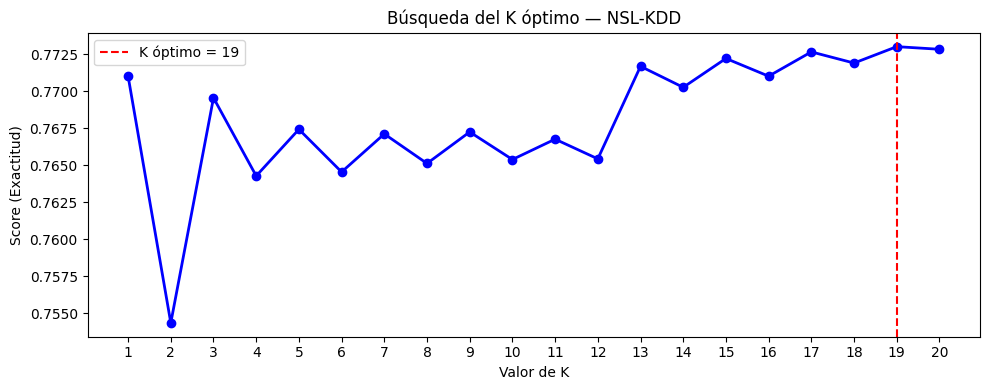

In [ ]:
# 2 — Graficar la curva de K

plt.figure(figsize=(10, 4))
plt.plot(k_range, scores, 'bo-', linewidth=2, markersize=6)
plt.axvline(x=mejor_k, color='red', linestyle='--',
            label=f'K óptimo = {mejor_k}')
plt.xlabel('Valor de K')
plt.ylabel('Score (Exactitud)')
plt.title('Búsqueda del K óptimo — NSL-KDD')
plt.legend()
plt.xticks(k_range)
plt.tight_layout()
plt.show()

In [ ]:
# 3 — Entrenar con el K óptimo

knn = KNeighborsClassifier(n_neighbors=mejor_k, n_jobs=-1)
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier(n_jobs=-1, n_neighbors=19)

In [ ]:
# PASO 4 — Predicciones

y_pred       = knn.predict(X_test_scaled)
y_pred_proba = knn.predict_proba(X_test_scaled)[:, 1]

In [ ]:
# PASO 5 — Matriz de confusión

cm = confusion_matrix(y_test, y_pred)
VN, FP, FN, VP = cm[0][0], cm[0][1], cm[1][0], cm[1][1]

print("\nMATRIZ DE CONFUSIÓN — KNN")
print(f"                Predijo Normal  Predijo Ataque")
print(f"  Real Normal  |   VN={VN:5}   |   FP={FP:5}   |")
print(f"  Real Ataque  |   FN={FN:5}   |   VP={VP:5}   |")



MATRIZ DE CONFUSIÓN — KNN
                Predijo Normal  Predijo Ataque
  Real Normal  |   VN= 9021   |   FP=  690   |
  Real Ataque  |   FN= 4427   |   VP= 8406   |


In [ ]:
# PASO 6 — Métricas

exactitud    = accuracy_score(y_test, y_pred)
precision    = precision_score(y_test, y_pred)
sensibilidad = recall_score(y_test, y_pred)
especif      = VN / (VN + FP)
f1           = f1_score(y_test, y_pred)
auc_roc      = roc_auc_score(y_test, y_pred_proba)

In [ ]:
print("\nMÉTRICAS — KNN")
print(f"  Exactitud      : {exactitud:.4f}  ({exactitud*100:.1f}%)")
print(f"  Precisión      : {precision:.4f}  ({precision*100:.1f}%)")
print(f"  Sensibilidad   : {sensibilidad:.4f}  ({sensibilidad*100:.1f}%)")
print(f"  Especificidad  : {especif:.4f}  ({especif*100:.1f}%)")
print(f"  F1-Score       : {f1:.4f}  ({f1*100:.1f}%)")
print(f"  AUC-ROC        : {auc_roc:.4f}")



MÉTRICAS — KNN
  Exactitud      : 0.7730  (77.3%)
  Precisión      : 0.9241  (92.4%)
  Sensibilidad   : 0.6550  (65.5%)
  Especificidad  : 0.9289  (92.9%)
  F1-Score       : 0.7667  (76.7%)
  AUC-ROC        : 0.8438


In [ ]:
# Guardar métricas para la tabla comparativa

metricas_knn = {
    'Exactitud': exactitud, 'Precisión': precision,
    'Sensibilidad': sensibilidad, 'Especificidad': especif,
    'F1-Score': f1, 'AUC-ROC': auc_roc
}

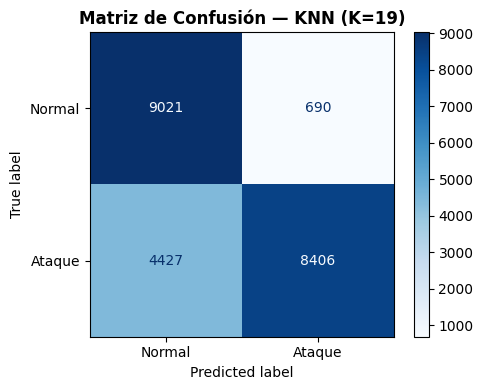

In [ ]:
# PASO 7 — Gráfico matriz de confusión

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['Normal', 'Ataque'])
disp.plot(cmap=plt.cm.Blues, ax=ax)
ax.set_title(f'Matriz de Confusión — KNN (K={mejor_k})',
             fontweight='bold')
plt.tight_layout()
plt.show()

## 2.2 Modelo 2 — ÁRBOL DE DECISIÓN

In [ ]:
from sklearn.tree import DecisionTreeClassifier, export_text

In [ ]:
# 1 — Buscar profundidad óptima

print("Buscando profundidad óptima.")

depth_range  = range(1, 21)
scores_train = []
scores_test  = []

for d in depth_range:
    arbol_d = DecisionTreeClassifier(
        max_depth=d,
        criterion='gini',
        class_weight='balanced',
        random_state=42
    )
    arbol_d.fit(X_train, y_train)   # árbol NO necesita datos escalados
    scores_train.append(arbol_d.score(X_train, y_train))
    scores_test.append(arbol_d.score(X_test, y_test))
    print(f"  depth={d:2d} → train={scores_train[-1]:.4f}  test={scores_test[-1]:.4f}")

mejor_depth = depth_range[scores_test.index(max(scores_test))]
print(f"\n✅ Mejor profundidad: {mejor_depth} | Score test: {max(scores_test):.4f}")

Buscando profundidad óptima.
  depth= 1 → train=0.9221  test=0.7999
  depth= 2 → train=0.9566  test=0.8153
  depth= 3 → train=0.9747  test=0.7970
  depth= 4 → train=0.9854  test=0.8164
  depth= 5 → train=0.9861  test=0.7896
  depth= 6 → train=0.9912  test=0.7971
  depth= 7 → train=0.9943  test=0.7872
  depth= 8 → train=0.9964  test=0.7811
  depth= 9 → train=0.9973  test=0.7934
  depth=10 → train=0.9979  test=0.7738
  depth=11 → train=0.9980  test=0.7786
  depth=12 → train=0.9984  test=0.7755
  depth=13 → train=0.9990  test=0.7704
  depth=14 → train=0.9991  test=0.7744
  depth=15 → train=0.9992  test=0.7748
  depth=16 → train=0.9993  test=0.7920
  depth=17 → train=0.9996  test=0.7841
  depth=18 → train=0.9997  test=0.7852
  depth=19 → train=0.9999  test=0.8135
  depth=20 → train=0.9999  test=0.7975

✅ Mejor profundidad: 4 | Score test: 0.8164


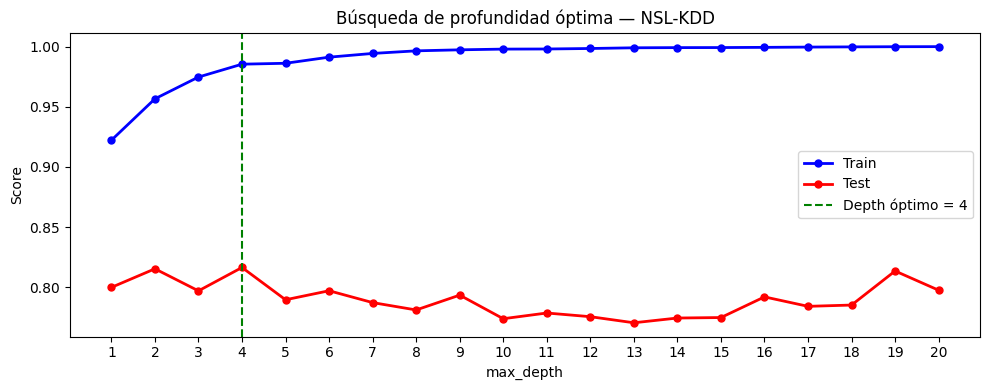

In [ ]:
# 2 — Graficar train vs test (detectar overfitting)

plt.figure(figsize=(10, 4))
plt.plot(depth_range, scores_train, 'b-o', linewidth=2,
         markersize=5, label='Train')
plt.plot(depth_range, scores_test,  'r-o', linewidth=2,
         markersize=5, label='Test')
plt.axvline(x=mejor_depth, color='green', linestyle='--',
            label=f'Depth óptimo = {mejor_depth}')
plt.xlabel('max_depth')
plt.ylabel('Score')
plt.title('Búsqueda de profundidad óptima — NSL-KDD')
plt.legend()
plt.xticks(depth_range)
plt.tight_layout()
plt.show()

In [ ]:
# 3 — Entrenar con la profundidad óptima

arbol = DecisionTreeClassifier(
    max_depth=mejor_depth,
    criterion='gini',
    class_weight='balanced',
    random_state=42
)
arbol.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=4, random_state=42)

In [ ]:
# 4 — Importancia de variables (top 10)

importancias = pd.DataFrame({
    'variable':    X_train.columns,
    'importancia': arbol.feature_importances_
}).sort_values('importancia', ascending=False)

print("\nTOP 10 VARIABLES MÁS IMPORTANTES:")
print(importancias.head(10).to_string(index=False))


TOP 10 VARIABLES MÁS IMPORTANTES:
                   variable  importancia
                  src_bytes     0.767423
              service_ecr_i     0.084343
               service_http     0.053542
     dst_host_same_srv_rate     0.029624
                        hot     0.025613
                  dst_bytes     0.020341
                  logged_in     0.009968
dst_host_same_src_port_rate     0.004043
       dst_host_rerror_rate     0.003200
   dst_host_srv_serror_rate     0.001377


In [ ]:
# 5 — Predicciones
y_pred_arbol       = arbol.predict(X_test)
y_pred_proba_arbol = arbol.predict_proba(X_test)[:, 1]


In [ ]:
# 6 — Matriz de confusión
cm_arbol = confusion_matrix(y_test, y_pred_arbol)
VN2, FP2, FN2, VP2 = cm_arbol[0][0], cm_arbol[0][1], cm_arbol[1][0], cm_arbol[1][1]

print("\nMATRIZ DE CONFUSIÓN — ÁRBOL")
print(f"                Predijo Normal  Predijo Ataque")
print(f"  Real Normal  |   VN={VN2:5}   |   FP={FP2:5}   |")
print(f"  Real Ataque  |   FN={FN2:5}   |   VP={VP2:5}   |")


MATRIZ DE CONFUSIÓN — ÁRBOL
                Predijo Normal  Predijo Ataque
  Real Normal  |   VN= 9401   |   FP=  310   |
  Real Ataque  |   FN= 3829   |   VP= 9004   |


In [ ]:
# 7 — Métricas
exactitud2    = accuracy_score(y_test, y_pred_arbol)
precision2    = precision_score(y_test, y_pred_arbol)
sensibilidad2 = recall_score(y_test, y_pred_arbol)
especif2      = VN2 / (VN2 + FP2)
f1_2          = f1_score(y_test, y_pred_arbol)
auc_roc2      = roc_auc_score(y_test, y_pred_proba_arbol)

In [ ]:
print("\nMÉTRICAS — ÁRBOL DE DECISIÓN")
print(f"  Exactitud      : {exactitud2:.4f}  ({exactitud2*100:.1f}%)")
print(f"  Precisión      : {precision2:.4f}  ({precision2*100:.1f}%)")
print(f"  Sensibilidad   : {sensibilidad2:.4f}  ({sensibilidad2*100:.1f}%)")
print(f"  Especificidad  : {especif2:.4f}  ({especif2*100:.1f}%)")
print(f"  F1-Score       : {f1_2:.4f}  ({f1_2*100:.1f}%)")
print(f"  AUC-ROC        : {auc_roc2:.4f}")


MÉTRICAS — ÁRBOL DE DECISIÓN
  Exactitud      : 0.8164  (81.6%)
  Precisión      : 0.9667  (96.7%)
  Sensibilidad   : 0.7016  (70.2%)
  Especificidad  : 0.9681  (96.8%)
  F1-Score       : 0.8131  (81.3%)
  AUC-ROC        : 0.8672


In [ ]:
# Guardar métricas para la tabla comparativa
metricas_arbol = {
    'Exactitud': exactitud2, 'Precisión': precision2,
    'Sensibilidad': sensibilidad2, 'Especificidad': especif2,
    'F1-Score': f1_2, 'AUC-ROC': auc_roc2
}


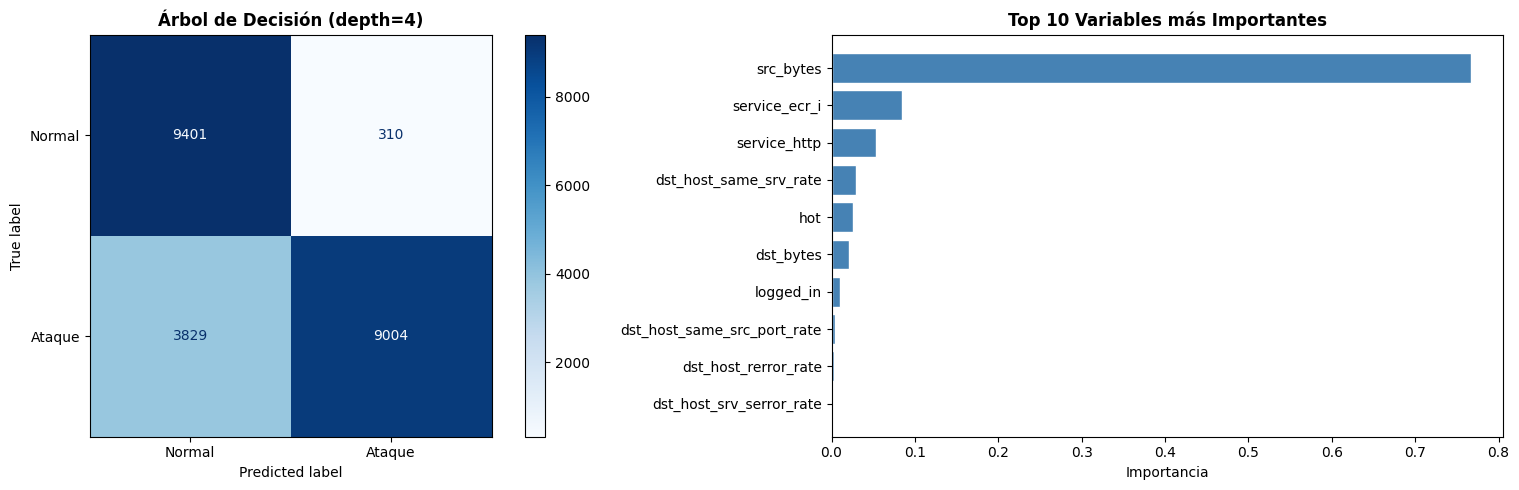

In [ ]:
# 8 — Gráficos
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Matriz de confusión
disp = ConfusionMatrixDisplay(confusion_matrix=cm_arbol,
                               display_labels=['Normal', 'Ataque'])
disp.plot(cmap=plt.cm.Blues, ax=axes[0])
axes[0].set_title(f'Árbol de Decisión (depth={mejor_depth})',
                   fontweight='bold')

# Importancia de variables top 10
top10 = importancias.head(10)
axes[1].barh(top10['variable'], top10['importancia'],
             color='steelblue', edgecolor='white')
axes[1].invert_yaxis()
axes[1].set_xlabel('Importancia')
axes[1].set_title('Top 10 Variables más Importantes', fontweight='bold')

plt.tight_layout()
plt.show()

## 2.3 Modelo 3 — K-MEANS (Clustering No Supervisado)

In [ ]:
from sklearn.cluster import KMeans

In [ ]:
# K-Means NO usa la etiqueta target durante el entrenamiento
# Agrupa las conexiones solo por similitud de comportamiento, después compara los clusters contra la etiqueta real

# 1 — Método del Codo para elegir K
print("Calculando inercia para K=1 a 10")

inercias = []
K_range  = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++',
                n_init=10, random_state=42)
    km.fit(X_train_scaled)
    inercias.append(km.inertia_)
    print(f"  K={k:2d} → inercia={km.inertia_:.2f}")

Calculando inercia para K=1 a 10
  K= 1 → inercia=499678.25
  K= 2 → inercia=305019.40
  K= 3 → inercia=218000.50
  K= 4 → inercia=177916.17
  K= 5 → inercia=161156.34
  K= 6 → inercia=147369.21
  K= 7 → inercia=138096.01
  K= 8 → inercia=127816.45
  K= 9 → inercia=119486.72
  K=10 → inercia=113548.31


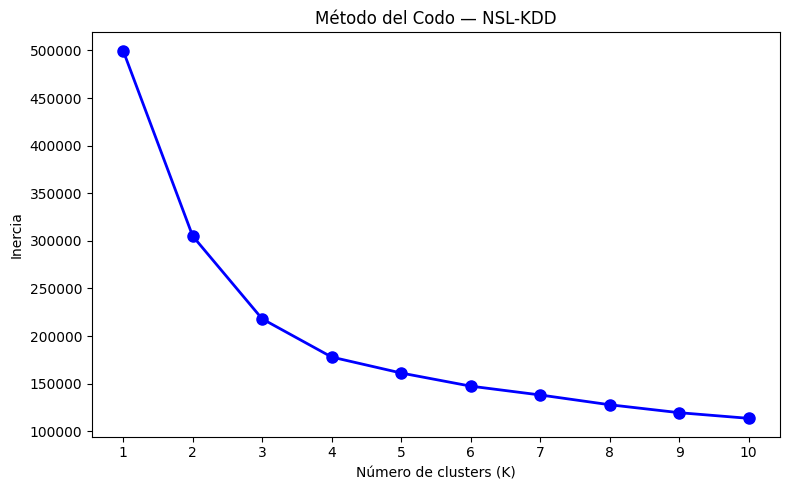

In [ ]:
# Graficar el codo
plt.figure(figsize=(8, 5))
plt.plot(K_range, inercias, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inercia')
plt.title('Método del Codo — NSL-KDD')
plt.xticks(K_range)
plt.tight_layout()
plt.show()

In [ ]:
# 2 — Entrenar con K=2 (binario: normal vs ataque)
# Elegimos K=2 porque el problema es binario en esencia, queremos ver si el algoritmo descubre esa estructura solo
print("\nEntrenando K-Means con K=2")

kmeans = KMeans(n_clusters=2, init='k-means++',
                n_init=10, random_state=42)
kmeans.fit(X_train_scaled)

# Asignamos clusters al test
clusters_test = kmeans.predict(X_test_scaled)


Entrenando K-Means con K=2


In [ ]:
# 3 — Verificar si los clusters coinciden con normal/ataque
df_validacion = pd.DataFrame({
    'cluster': clusters_test,
    'target_real': y_test.values
})

print("\nDistribución real por cluster descubierto:")
tabla = df_validacion.groupby('cluster').agg(
    total=('target_real', 'size'),
    normales=('target_real', lambda x: (x == 0).sum()),
    ataques=('target_real', lambda x: (x == 1).sum())
).reset_index()
tabla['pct_ataque'] = (tabla['ataques'] / tabla['total'] * 100).round(1)
tabla['pct_normal'] = (tabla['normales'] / tabla['total'] * 100).round(1)
print(tabla.to_string(index=False))


Distribución real por cluster descubierto:
 cluster  total  normales  ataques  pct_ataque  pct_normal
       0  20329      9706    10623        52.3        47.7
       1   2215         5     2210        99.8         0.2


In [ ]:
# 4 — Identificar qué cluster representa ataques

# El cluster con mayor % de ataques = cluster de ataque
cluster_ataque = tabla.loc[tabla['pct_ataque'].idxmax(), 'cluster']
cluster_normal = 1 - cluster_ataque
print(f"\nCluster {cluster_ataque} → mayormente ATAQUES")
print(f"Cluster {cluster_normal} → mayormente NORMAL")


Cluster 1 → mayormente ATAQUES
Cluster 0 → mayormente NORMAL


In [ ]:
# 5 — Repetir con K=5 para ver tipos de ataque

print("K-MEANS CON K=5 — Buscando tipos de tráfico")

kmeans5 = KMeans(n_clusters=5, init='k-means++',
                 n_init=10, random_state=42)
kmeans5.fit(X_train_scaled)
clusters5_test = kmeans5.predict(X_test_scaled)

df_val5 = pd.DataFrame({
    'cluster':      clusters5_test,
    'target_real':  y_test.values
})

tabla5 = df_val5.groupby('cluster').agg(
    total=('target_real', 'size'),
    ataques=('target_real', lambda x: (x == 1).sum())
).reset_index()
tabla5['pct_ataque'] = (tabla5['ataques'] / tabla5['total'] * 100).round(1)
print(tabla5.to_string(index=False))

K-MEANS CON K=5 — Buscando tipos de tráfico
 cluster  total  ataques  pct_ataque
       0   7943     1292        16.3
       1   2240     2235        99.8
       2   4834     4753        98.3
       3   2210      660        29.9
       4   5317     3893        73.2


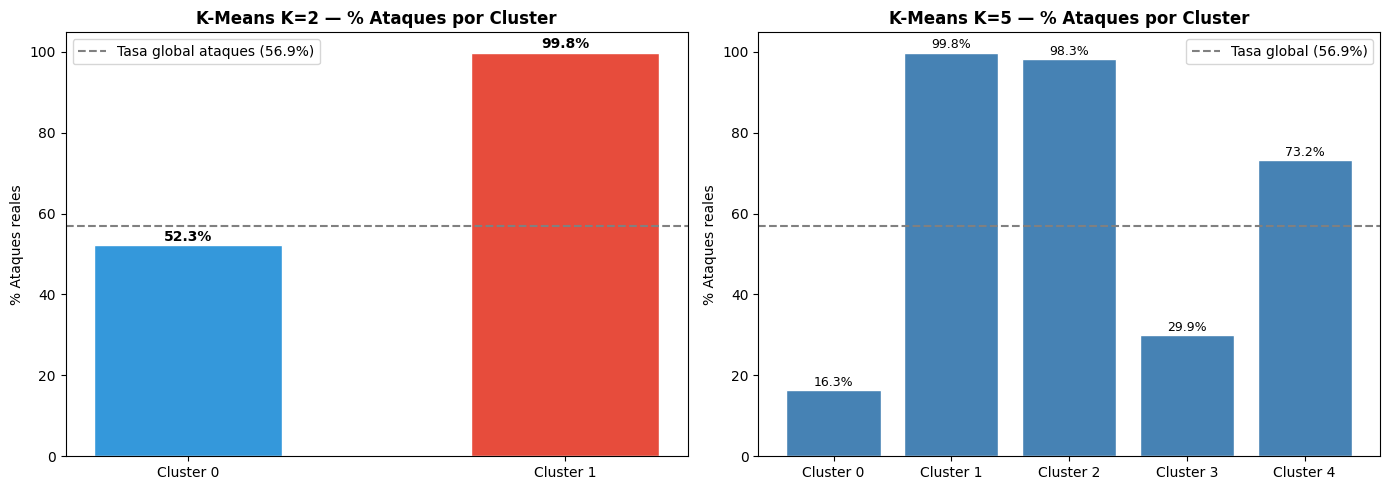

In [ ]:
# 6 — Gráfico comparativo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K=2 — proporción por cluster
colores = ['#3498db', '#e74c3c']
axes[0].bar(['Cluster 0', 'Cluster 1'],
            tabla['pct_ataque'],
            color=colores, edgecolor='white', width=0.5)
axes[0].axhline(y=56.9, color='gray', linestyle='--',
                label='Tasa global ataques (56.9%)')
axes[0].set_ylabel('% Ataques reales')
axes[0].set_title('K-Means K=2 — % Ataques por Cluster',
                   fontweight='bold')
axes[0].legend()
for i, v in enumerate(tabla['pct_ataque']):
    axes[0].text(i, v + 1, f'{v}%', ha='center', fontweight='bold')

# K=5 — distribución
axes[1].bar([f'Cluster {c}' for c in tabla5['cluster']],
            tabla5['pct_ataque'],
            color='steelblue', edgecolor='white')
axes[1].axhline(y=56.9, color='gray', linestyle='--',
                label='Tasa global (56.9%)')
axes[1].set_ylabel('% Ataques reales')
axes[1].set_title('K-Means K=5 — % Ataques por Cluster',
                   fontweight='bold')
axes[1].legend()
for i, v in enumerate(tabla5['pct_ataque']):
    axes[1].text(i, v + 1, f'{v}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 2.4 Modelo 4 — NAIVE BAYES

In [ ]:
from sklearn.naive_bayes import GaussianNB
import time

In [ ]:
inicio = time.time()

# 1 — Crear y entrenar el modelo

# GaussianNB asume que cada variable sigue una distribución gaussiana — no tiene hiperparámetros que optimizar

nb = GaussianNB()
nb.fit(X_train_scaled, y_train)

tiempo = time.time() - inicio
print(f"✅ Entrenado en {tiempo:.2f} segundos")

✅ Entrenado en 0.15 segundos


In [ ]:
# 2 — Predicciones
y_pred_nb  = nb.predict(X_test_scaled)
y_proba_nb = nb.predict_proba(X_test_scaled)[:, 1]


In [ ]:
# 3 — Matriz de confusión
cm_nb = confusion_matrix(y_test, y_pred_nb)
VN3, FP3, FN3, VP3 = cm_nb[0][0], cm_nb[0][1], cm_nb[1][0], cm_nb[1][1]

print("\nMATRIZ DE CONFUSIÓN — NAIVE BAYES")
print(f"                Predijo Normal  Predijo Ataque")
print(f"  Real Normal  |   VN={VN3:5}   |   FP={FP3:5}   |")
print(f"  Real Ataque  |   FN={FN3:5}   |   VP={VP3:5}   |")


MATRIZ DE CONFUSIÓN — NAIVE BAYES
                Predijo Normal  Predijo Ataque
  Real Normal  |   VN= 9648   |   FP=   63   |
  Real Ataque  |   FN= 9747   |   VP= 3086   |


In [ ]:
# 4 — Métricas
exactitud3    = accuracy_score(y_test, y_pred_nb)
precision3    = precision_score(y_test, y_pred_nb)
sensibilidad3 = recall_score(y_test, y_pred_nb)
especif3      = VN3 / (VN3 + FP3)
f1_3          = f1_score(y_test, y_pred_nb)
auc_roc3      = roc_auc_score(y_test, y_proba_nb)

print("\nMÉTRICAS — NAIVE BAYES")
print(f"  Exactitud      : {exactitud3:.4f}  ({exactitud3*100:.1f}%)")
print(f"  Precisión      : {precision3:.4f}  ({precision3*100:.1f}%)")
print(f"  Sensibilidad   : {sensibilidad3:.4f}  ({sensibilidad3*100:.1f}%)")
print(f"  Especificidad  : {especif3:.4f}  ({especif3*100:.1f}%)")
print(f"  F1-Score       : {f1_3:.4f}  ({f1_3*100:.1f}%)")
print(f"  AUC-ROC        : {auc_roc3:.4f}")


MÉTRICAS — NAIVE BAYES
  Exactitud      : 0.5649  (56.5%)
  Precisión      : 0.9800  (98.0%)
  Sensibilidad   : 0.2405  (24.0%)
  Especificidad  : 0.9935  (99.4%)
  F1-Score       : 0.3862  (38.6%)
  AUC-ROC        : 0.7984


In [ ]:
# Guardar métricas
metricas_nb = {
    'Exactitud': exactitud3, 'Precisión': precision3,
    'Sensibilidad': sensibilidad3, 'Especificidad': especif3,
    'F1-Score': f1_3, 'AUC-ROC': auc_roc3
}


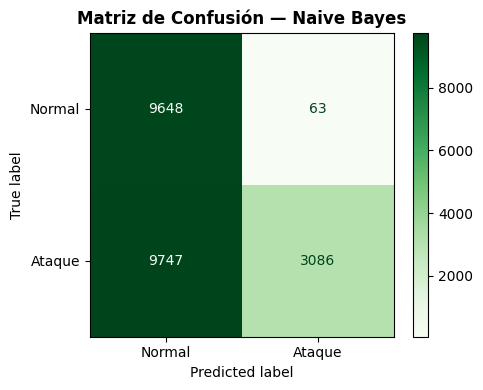

In [ ]:
# MATRIZ DE CONFUSIÓN NAIVE BAYES

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_nb,
                               display_labels=['Normal', 'Ataque'])
disp.plot(cmap=plt.cm.Greens, ax=ax)
ax.set_title('Matriz de Confusión — Naive Bayes', fontweight='bold')
plt.tight_layout()
plt.show()

## 2.5 COMPARATIVA FINAL

In [ ]:
# ============================================================
# TABLA COMPARATIVA FINAL — KNN vs ÁRBOL vs NAIVE BAYES
# ============================================================


print("COMPARATIVA FINAL DE MODELOS — NSL-KDD")
print("=" * 68)
print(f"{'Métrica':<16} {'KNN':>10} {'Árbol':>10} {'Naive Bayes':>12}  Mejor")
print("-" * 68)

nombres = ['Exactitud', 'Precisión', 'Sensibilidad',
           'Especificidad', 'F1-Score', 'AUC-ROC']

for nombre in nombres:
    knn_v = metricas_knn[nombre]
    arb_v = metricas_arbol[nombre]
    nb_v  = metricas_nb[nombre]
    vals  = {'KNN': knn_v, 'Árbol': arb_v, 'Naive Bayes': nb_v}
    mejor = max(vals, key=vals.get)
    print(f"  {nombre:<14} {knn_v:>10.4f} {arb_v:>10.4f} {nb_v:>12.4f}  {mejor} ★")

COMPARATIVA FINAL DE MODELOS — NSL-KDD
Métrica                 KNN      Árbol  Naive Bayes  Mejor
--------------------------------------------------------------------
  Exactitud          0.7730     0.8164       0.5649  Árbol ★
  Precisión          0.9241     0.9667       0.9800  Naive Bayes ★
  Sensibilidad       0.6550     0.7016       0.2405  Árbol ★
  Especificidad      0.9289     0.9681       0.9935  Naive Bayes ★
  F1-Score           0.7667     0.8131       0.3862  Árbol ★
  AUC-ROC            0.8438     0.8672       0.7984  Árbol ★


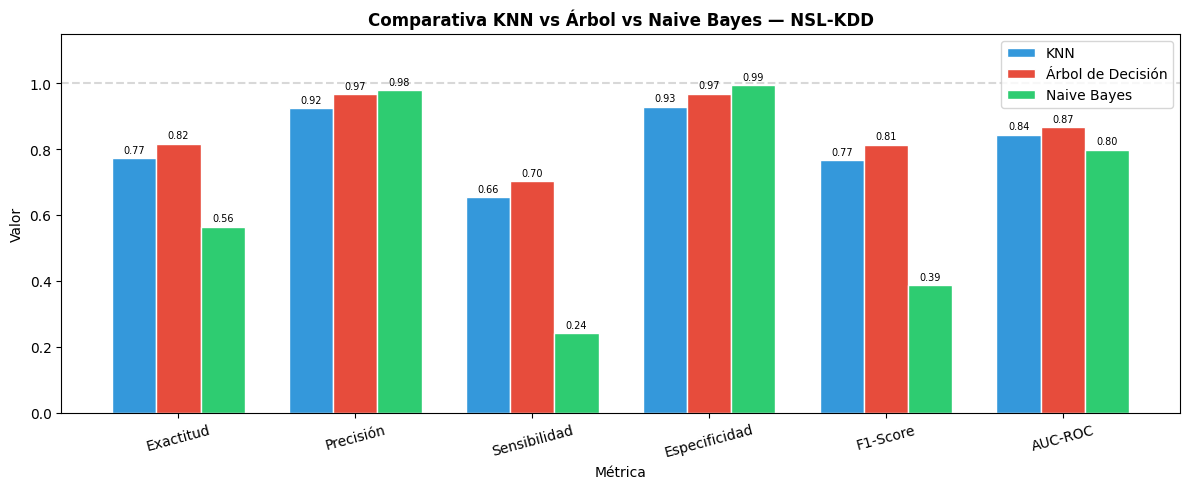

In [ ]:
# GRÁFICO  COMPARATIVA 3 MODELOS

fig, ax = plt.subplots(figsize=(12, 5))

x     = range(len(nombres))
width = 0.25

vals_knn = [metricas_knn[n]   for n in nombres]
vals_arb = [metricas_arbol[n] for n in nombres]
vals_nb  = [metricas_nb[n]    for n in nombres]

bars1 = ax.bar([i - width for i in x], vals_knn,
               width, label='KNN', color='#3498db', edgecolor='white')
bars2 = ax.bar([i          for i in x], vals_arb,
               width, label='Árbol de Decisión',
               color='#e74c3c', edgecolor='white')
bars3 = ax.bar([i + width for i in x], vals_nb,
               width, label='Naive Bayes',
               color='#2ecc71', edgecolor='white')

ax.set_xlabel('Métrica')
ax.set_ylabel('Valor')
ax.set_title('Comparativa KNN vs Árbol vs Naive Bayes — NSL-KDD',
             fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(nombres, rotation=15)
ax.set_ylim(0, 1.15)
ax.legend()
ax.axhline(y=1.0, color='gray', linestyle='--', alpha=0.3)

# Valores encima de cada barra
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.01,
                f'{bar.get_height():.2f}',
                ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.show()

In [ ]:
# Demostración con predict_proba del Árbol
UMBRAL = 0.90
alertas_criticas = (y_pred_proba_arbol >= UMBRAL).sum()
print(f"Ejemplo con umbral = {UMBRAL} (Árbol de Decisión):")
print(f"  Conexiones con prob_ataque >= {UMBRAL}: {alertas_criticas:,}")
print(f"  Estas {alertas_criticas:,} conexiones activarían")
print(f"  el aislamiento automático del equipo")

Ejemplo con umbral = 0.9 (Árbol de Decisión):
  Conexiones con prob_ataque >= 0.9: 9,314
  Estas 9,314 conexiones activarían
  el aislamiento automático del equipo


# Conclusión General — Detección de Intrusiones con Machine Learning



### Resumen de resultados

| Métrica | KNN (K=19) | Árbol (depth=4) | Naive Bayes | Mejor |
|---|---|---|---|---|
| Exactitud | 77.3% | **81.6%** | 56.5% | Árbol ★ |
| Precisión | 92.4% | 96.7% | **98.0%** | Naive Bayes ★ |
| Sensibilidad | 65.5% | **70.2%** | 24.0% | Árbol ★ |
| Especificidad | 92.9% | 96.8% | **99.4%** | Naive Bayes ★ |
| F1-Score | 76.7% | **81.3%** | 38.6% | Árbol ★ |
| AUC-ROC | 0.844 | **0.867** | 0.798 | Árbol ★ |
| Tiempo entrenamiento | ~2 min | ~segundos | **0.23 seg** | Naive Bayes ★ |

---

### Respuestas a las preguntas de la consigna

**¿Se puede predecir vulnerabilidad del sistema?**
Sí. Los tres modelos clasifican conexiones de red como normales
o ataques analizando 118 características del tráfico (bytes
transferidos, protocolo, tipo de servicio, tasas de error, etc.).
El Árbol de Decisión logra 96.7% de Precisión — cuando predice
un ataque, casi siempre está en lo correcto.

**¿Con qué precisión?**
El modelo recomendado es el Árbol de Decisión (depth=4):
- Detecta el 70.2% de los ataques reales (Sensibilidad)
- Cuando alerta, acierta el 96.7% de las veces (Precisión)
- AUC-ROC de 0.867 — buena capacidad discriminativa general

De cada 10 ataques que ocurren en la red, el sistema detecta 7.

**¿Se puede aislar automáticamente el equipo?**
Sí. Usando predict_proba() el modelo devuelve la probabilidad
de que cada conexión sea un ataque. Con un umbral de 0.90,
las conexiones con probabilidad mayor al 90% activan
automáticamente el aislamiento del equipo afectado.

---

### ¿Por qué el Árbol de Decisión es el modelo recomendado?

En ciberseguridad la métrica crítica es la **Sensibilidad**
(detectar la mayor cantidad de ataques reales). Un ataque
no detectado (Falso Negativo) puede comprometer toda la red.
Una falsa alarma (Falso Positivo) solo requiere una
verificación manual.

- **KNN**: buena precisión pero Sensibilidad de 65.5% —
  se pierde demasiados ataques reales.
- **Árbol**: mejor balance general. Sensibilidad 70.2%,
  Precisión 96.7%, F1 81.3%. Además es completamente
  interpretable — se puede explicar cada decisión.
- **Naive Bayes**: Sensibilidad de solo 24% — inaceptable
  en producción. Se pierde el 76% de los ataques porque
  el supuesto de independencia entre variables no se cumple
  en tráfico de red (src_bytes, dst_bytes y serror_rate
  están fuertemente correlacionadas en los ataques DoS).

### ¿Qué aportó K-Means?

K-Means descubrió sin usar la etiqueta que los datos tienen
una estructura de riesgo natural. Con K=5 encontró clusters
con tasas de ataque del 99.8%, 98.3%, 73.2%, 29.9% y 16.3%
— una jerarquía de vulnerabilidad que puede usarse para
priorizar qué conexiones monitorear primero.

### Limitación principal

La Sensibilidad del 70.2% significa que el 29.8% de los
ataques no son detectados. Para mejorar esto el siguiente
paso sería aplicar Random Forest o XGBoost — algoritmos
basados en árboles que combinan cientos de modelos y
típicamente logran Sensibilidad superior al 90% en este
dataset según la literatura académica.